# Ghost Hunter 2D — AI Evaluation & Visualization Notebook
**Course:** Artificial Intelligence Lab (AI-2002) — NUCES-FAST Karachi  
**Project:** Ghost Hunter 2D (CSP Level Generation, A* Pathfinding, HMM Belief Tracking, and Autonomous Goal-Based Agent)  

This notebook runs reproducible simulations against the `ghost_hunter_2d` engine and generates all evaluation charts and tables.

In [1]:
import sys
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add ghost_hunter_2d to Python path
PROJECT_DIR = Path("ghost_hunter_2d").resolve()
if not PROJECT_DIR.exists():
    PROJECT_DIR = Path(".").resolve()
sys.path.insert(0, str(PROJECT_DIR))

from config import DIFFICULTIES, SENSOR_SIGMA
from core.csp import generate_level
from core.ai_agent import AIHunterAgent
from core.session import GameSession

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
print("Engine loaded from:", PROJECT_DIR)

Engine loaded from: D:\5th Semester\AI Lab\project\ghost_hunter_2d


## 1. Procedural Dataset: CSP Level Generation Benchmark
We evaluate the two-stage CSP solver (Stage 1: wall placement with BFS connectivity constraint checking & undo; Stage 2: spawn backtracking with forward checking) across 15 random seeds per difficulty.

In [2]:
csp_rows = []
for d in DIFFICULTIES:
    for seed in range(15):
        rng = random.Random(seed)
        t0 = time.perf_counter()
        lvl = generate_level(d.size, d.wall_count, d.min_spawn_distance, rng, with_partner=True)
        elapsed_ms = (time.perf_counter() - t0) * 1000.0
        csp_rows.append({
            "Difficulty": d.name,
            "Grid Size": f"{d.size}x{d.size}",
            "Wall Count": d.wall_count,
            "Solve Time (ms)": elapsed_ms,
            "Attempts": lvl.stats.attempts,
            "Wall Undos": lvl.stats.wall_undos,
            "Spawn Backtracks": lvl.stats.spawn_backtracks,
        })

df_csp = pd.DataFrame(csp_rows)
display(df_csp.groupby(["Difficulty", "Grid Size", "Wall Count"], sort=False).agg(
    Mean_Time_ms=("Solve Time (ms)", "mean"),
    Std_Time_ms=("Solve Time (ms)", "std"),
    Mean_Wall_Undos=("Wall Undos", "mean"),
    Mean_Backtracks=("Spawn Backtracks", "mean"),
).round(2))

,,,Mean_Time_ms,Std_Time_ms,Mean_Wall_Undos,Mean_Backtracks
Difficulty,Grid Size,Wall Count,,,,
Beginner,8x8,6,0.76,0.25,0.07,0.0
Intermediate,12x12,22,5.52,1.68,0.40,0.0
Professional,18x18,58,24.72,1.65,1.07,0.0
Expert,25x25,125,102.51,6.35,2.13,0.0


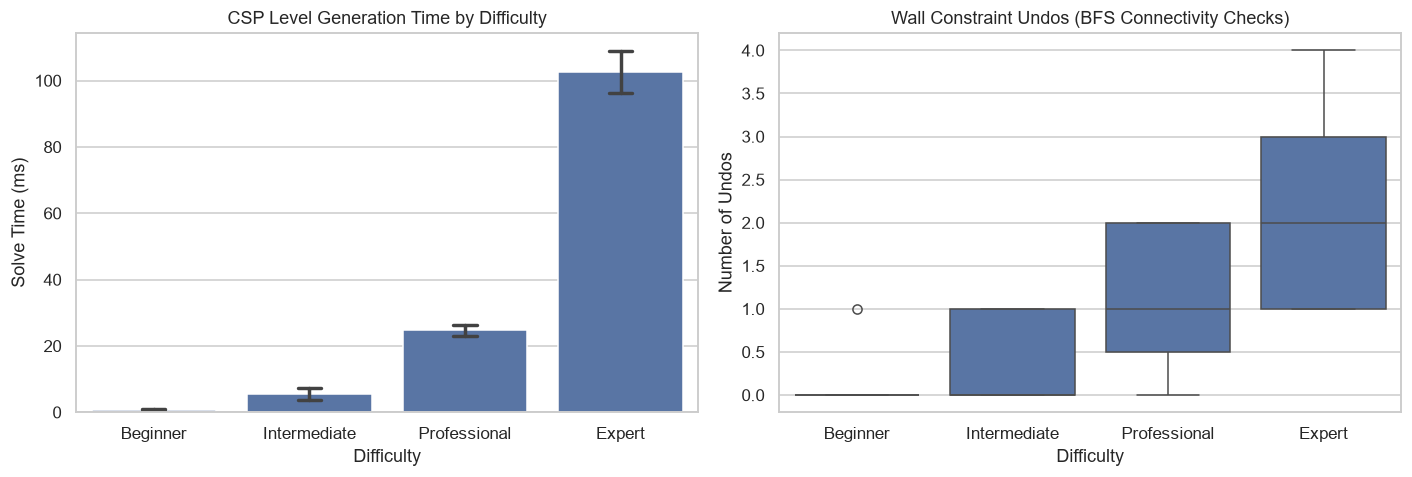

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(data=df_csp, x="Difficulty", y="Solve Time (ms)", ax=axes[0], errorbar="sd", capsize=0.15)
axes[0].set_title("CSP Level Generation Time by Difficulty")
axes[0].set_ylabel("Solve Time (ms)")

sns.boxplot(data=df_csp, x="Difficulty", y="Wall Undos", ax=axes[1])
axes[1].set_title("Wall Constraint Undos (BFS Connectivity Checks)")
axes[1].set_ylabel("Number of Undos")

plt.tight_layout()
plt.show()

## 2. HMM Belief Tracking & Entropy Convergence
We track Shannon entropy $H(b_t) = -\sum_i b_t(i)\log_2 b_t(i)$ and the posterior probability assigned to the ghost's true cell during a simulated Expert hunt.

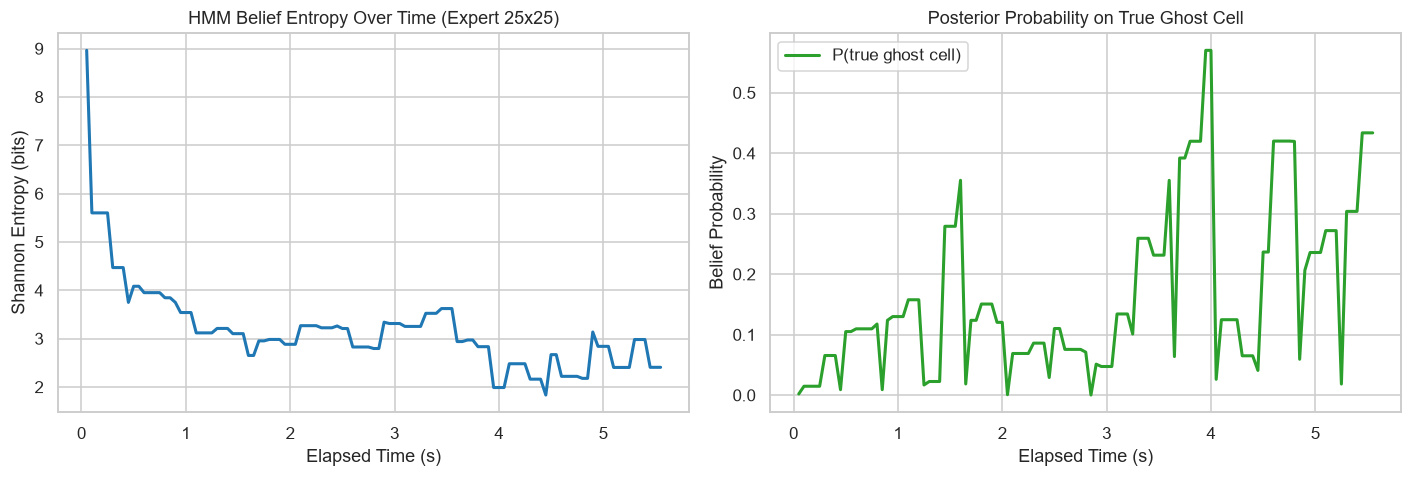

In [4]:
d_exp = DIFFICULTIES[3]  # Expert 25x25
rng = random.Random(42)
ai = AIHunterAgent(move_rate=d_exp.ai_speed)
sess = GameSession(d_exp, rng, agent=ai)

trace = []
dt = 0.05
while not sess.caught and sess.elapsed < 60.0:
    sess.update(dt)
    b = ai.belief.belief
    nz = b[b > 1e-12]
    entropy = float(-np.sum(nz * np.log2(nz)))
    true_prob = ai.belief.probability(sess.env.ghost)
    trace.append({
        "Time (s)": sess.elapsed,
        "Entropy (bits)": entropy,
        "True Cell Prob": true_prob,
        "True Distance": sess.grid.distance(sess.env.hunter, sess.env.ghost),
    })

df_trace = pd.DataFrame(trace)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(df_trace["Time (s)"], df_trace["Entropy (bits)"], color="tab:blue", lw=2)
axes[0].set_title("HMM Belief Entropy Over Time (Expert 25x25)")
axes[0].set_xlabel("Elapsed Time (s)")
axes[0].set_ylabel("Shannon Entropy (bits)")

axes[1].plot(df_trace["Time (s)"], df_trace["True Cell Prob"], color="tab:green", lw=2, label="P(true ghost cell)")
axes[1].set_title("Posterior Probability on True Ghost Cell")
axes[1].set_xlabel("Elapsed Time (s)")
axes[1].set_ylabel("Belief Probability")
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Autonomous AI Hunter (`Sir Nadeem`) Performance Evaluation
We simulate 15 independent hunts per difficulty level and measure Catch Rate, Time-to-Catch, Moves Taken, and Final Score.

In [5]:
hunt_rows = []
for d in DIFFICULTIES:
    for seed in range(15):
        rng = random.Random(100 + seed)
        ai = AIHunterAgent(move_rate=d.ai_speed)
        sess = GameSession(d, rng, agent=ai)
        while not sess.caught and sess.elapsed < 120.0:
            sess.update(0.05)
        hunt_rows.append({
            "Difficulty": d.name,
            "Caught": int(sess.caught),
            "Time (s)": sess.elapsed,
            "Moves": sess.moves,
            "Score": sess.score.final if sess.score else 0,
        })

df_hunt = pd.DataFrame(hunt_rows)
display(df_hunt.groupby("Difficulty", sort=False).agg(
    Catch_Rate=("Caught", "mean"),
    Avg_Time_s=("Time (s)", "mean"),
    Avg_Moves=("Moves", "mean"),
    Avg_Score=("Score", "mean"),
).round(2))

,Catch_Rate,Avg_Time_s,Avg_Moves,Avg_Score
Difficulty,,,,
Beginner,1.0,3.06,16.07,9526.67
Intermediate,1.0,3.01,16.60,14277.13
Professional,1.0,5.08,29.33,18320.00
Expert,1.0,5.49,33.53,27169.00


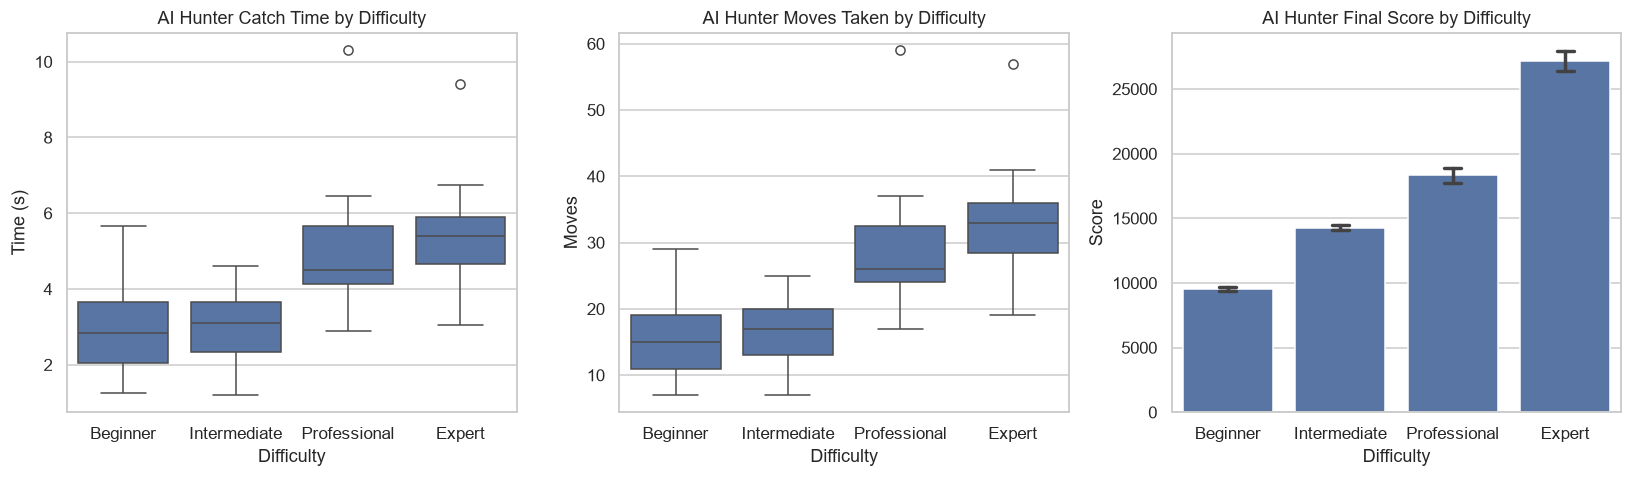

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.boxplot(data=df_hunt, x="Difficulty", y="Time (s)", ax=axes[0])
axes[0].set_title("AI Hunter Catch Time by Difficulty")

sns.boxplot(data=df_hunt, x="Difficulty", y="Moves", ax=axes[1])
axes[1].set_title("AI Hunter Moves Taken by Difficulty")

sns.barplot(data=df_hunt, x="Difficulty", y="Score", ax=axes[2], errorbar="sd", capsize=0.15)
axes[2].set_title("AI Hunter Final Score by Difficulty")

plt.tight_layout()
plt.show()

## 4. Sensor Noise (`SENSOR_SIGMA`) Sensitivity Analysis
We evaluate how Gaussian distance-sensor noise $\sigma \in \{0.5, 1.0, 1.5, 2.5, 4.0\}$ affects the AI Hunter's catch time and moves on Intermediate (`12x12`).

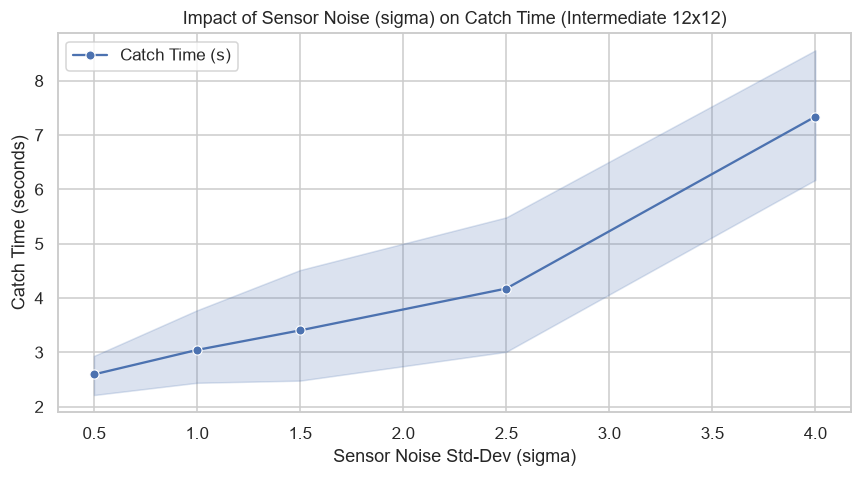

In [7]:
d_mid = DIFFICULTIES[1]  # Intermediate 12x12
sigma_rows = []
for sigma in [0.5, 1.0, 1.5, 2.5, 4.0]:
    for seed in range(10):
        rng = random.Random(200 + seed)
        ai = AIHunterAgent(sigma=sigma, move_rate=d_mid.ai_speed)
        sess = GameSession(d_mid, rng, agent=ai)
        sess.env.sigma = sigma
        while not sess.caught and sess.elapsed < 120.0:
            sess.update(0.05)
        sigma_rows.append({
            "Sigma": sigma,
            "Time (s)": sess.elapsed,
            "Moves": sess.moves,
        })

df_sigma = pd.DataFrame(sigma_rows)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.lineplot(data=df_sigma, x="Sigma", y="Time (s)", marker="o", label="Catch Time (s)", ax=ax)
ax.set_title("Impact of Sensor Noise (sigma) on Catch Time (Intermediate 12x12)")
ax.set_xlabel("Sensor Noise Std-Dev (sigma)")
ax.set_ylabel("Catch Time (seconds)")
plt.tight_layout()
plt.show()